# CSE427 Project : A Comparative Machine Learning Approach for Predicting Insomnia and Sleep Quality Degradation among Bangladeshi University Students

## Group 4

1.   Jaky Ahmed Chowdhury (22201616)
2.   Farhana Tasnim Eva   (22299431)
3.   Md. Khairul Ashik    (22201403)




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/Jaky-Chow01/project-cse-427/refs/heads/main/Merged%20Dataset%20(Collected%2BOurs).csv')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (811, 13)


,Department,Gender,Age,SleepDuration,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,BloodPressure(systolic/diastolic),HeartRate(bpm),DailySteps,AcademicLevel,SleepDisorder
0,Economics,Female,24,Lessthan4hours,Poor,30,VeryLow,Obese(BMI≥30),118/80,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Postgraduate,Insomnia
1,EEE,Male,20,5–6hours,VeryPoor,100,Low,Overweight(BMI25–29.9),117/70,70.0,"Morethan16,000:(gymsession+power-walking+eveni...",Level-1,NoSleepDisorder
2,NE,Male,21,5–6hours,Good,110,Low,Normal(BMI18.5–24.9),124/74,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-2,SleepApnea
3,DVM,Male,22,7–8hours,VeryPoor,36,Low,Normal(BMI18.5–24.9),119/65,83.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-4,SleepApnea
4,CSE,Female,20,6–7hours,Average,100,Moderate,Overweight(BMI25–29.9),117/77,85.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-2,SleepApnea


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811 entries, 0 to 810
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Department                         811 non-null    object 
 1   Gender                             811 non-null    object 
 2   Age                                811 non-null    int64  
 3   SleepDuration                      811 non-null    object 
 4   QualityofSleep                     811 non-null    object 
 5   PhysicalActivityLevel              811 non-null    int64  
 6   StressLevel                        811 non-null    object 
 7   BMICategory                        811 non-null    object 
 8   BloodPressure(systolic/diastolic)  751 non-null    object 
 9   HeartRate(bpm)                     737 non-null    float64
 10  DailySteps                         811 non-null    object 
 11  AcademicLevel                      811 non-null    object 

In [ ]:
df.describe(include='all')

,Department,Gender,Age,SleepDuration,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,BloodPressure(systolic/diastolic),HeartRate(bpm),DailySteps,AcademicLevel,SleepDisorder
count,811,811,811.000000,811,811,811.000000,811,811,751,737.000000,811,811,773
unique,15,3,NaN,6,5,NaN,5,4,547,NaN,5,5,3
top,CSE,Male,NaN,4–5hours,Average,NaN,High,Normal(BMI18.5–24.9),118/69,NaN,"Morethan16,000:(gymsession+power-walking+eveni...",Level-2,SleepApnea
freq,156,408,NaN,148,183,NaN,168,453,5,NaN,173,192,321
mean,NaN,NaN,21.875462,NaN,NaN,61.933416,NaN,NaN,NaN,74.945726,NaN,NaN,NaN
std,NaN,NaN,2.153499,NaN,NaN,33.633214,NaN,NaN,NaN,11.832265,NaN,NaN,NaN
min,NaN,NaN,18.000000,NaN,NaN,10.000000,NaN,NaN,NaN,55.000000,NaN,NaN,NaN
25%,NaN,NaN,20.000000,NaN,NaN,30.000000,NaN,NaN,NaN,66.000000,NaN,NaN,NaN
50%,NaN,NaN,22.000000,NaN,NaN,70.000000,NaN,NaN,NaN,74.000000,NaN,NaN,NaN
75%,NaN,NaN,23.000000,NaN,NaN,90.000000,NaN,NaN,NaN,82.000000,NaN,NaN,NaN


In [ ]:
df.nunique()

,0
Department,15
Gender,3
Age,11
SleepDuration,6
QualityofSleep,5
PhysicalActivityLevel,16
StressLevel,5
BMICategory,4
BloodPressure(systolic/diastolic),547
HeartRate(bpm),54


In [ ]:
print("Missing values per column:")
df.isnull().sum()

Missing values per column:


,0
Department,0
Gender,0
Age,0
SleepDuration,0
QualityofSleep,0
PhysicalActivityLevel,0
StressLevel,0
BMICategory,0
BloodPressure(systolic/diastolic),60
HeartRate(bpm),74


In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print(f"Number of Categorical values: {len(cat_cols)}")
print("Categorical Variables:", cat_cols)
print()
print(f"Number of Numerical values: {len(num_cols)}")
print("Numerical Variables:", num_cols)

Number of Categorical values: 10
Categorical Variables: ['Department', 'Gender', 'SleepDuration', 'QualityofSleep', 'StressLevel', 'BMICategory', 'BloodPressure(systolic/diastolic)', 'DailySteps', 'AcademicLevel', 'SleepDisorder']

Number of Numerical values: 3
Numerical Variables: ['Age', 'PhysicalActivityLevel', 'HeartRate(bpm)']


SleepDisorder
SleepApnea         321
NoSleepDisorder    249
Insomnia           203
NaN                 38
Name: count, dtype: int64

Total samples: 811


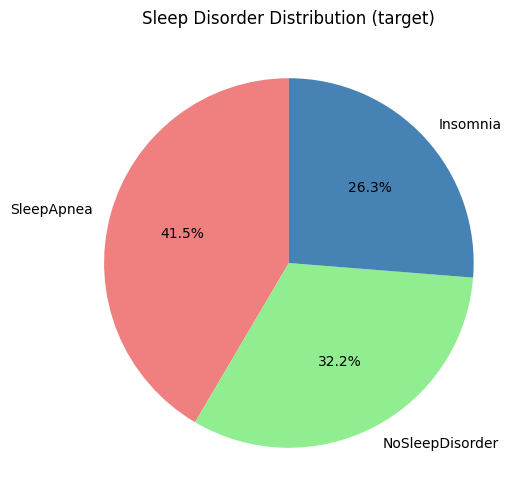

In [ ]:
print(df['SleepDisorder'].value_counts(dropna=False))

print("\nTotal samples:", len(df['SleepDisorder']))
plt.figure(figsize=(6,6))
ax = df['SleepDisorder'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['lightcoral', 'lightgreen', 'steelblue'])
ax.set_ylabel('')
plt.title('Sleep Disorder Distribution (target)')
plt.show()



                            Age  PhysicalActivityLevel  HeartRate(bpm)
Age                    1.000000               0.086100        0.062187
PhysicalActivityLevel  0.086100               1.000000        0.033795
HeartRate(bpm)         0.062187               0.033795        1.000000


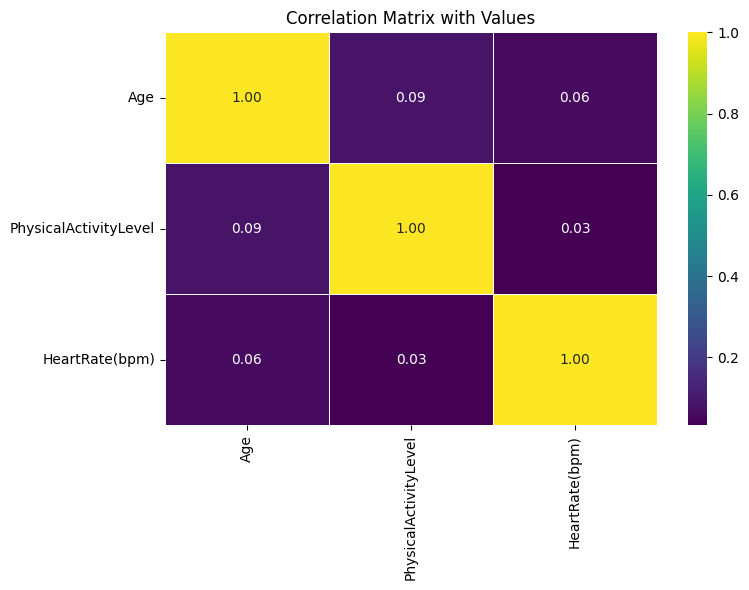

In [ ]:
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix with Values')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

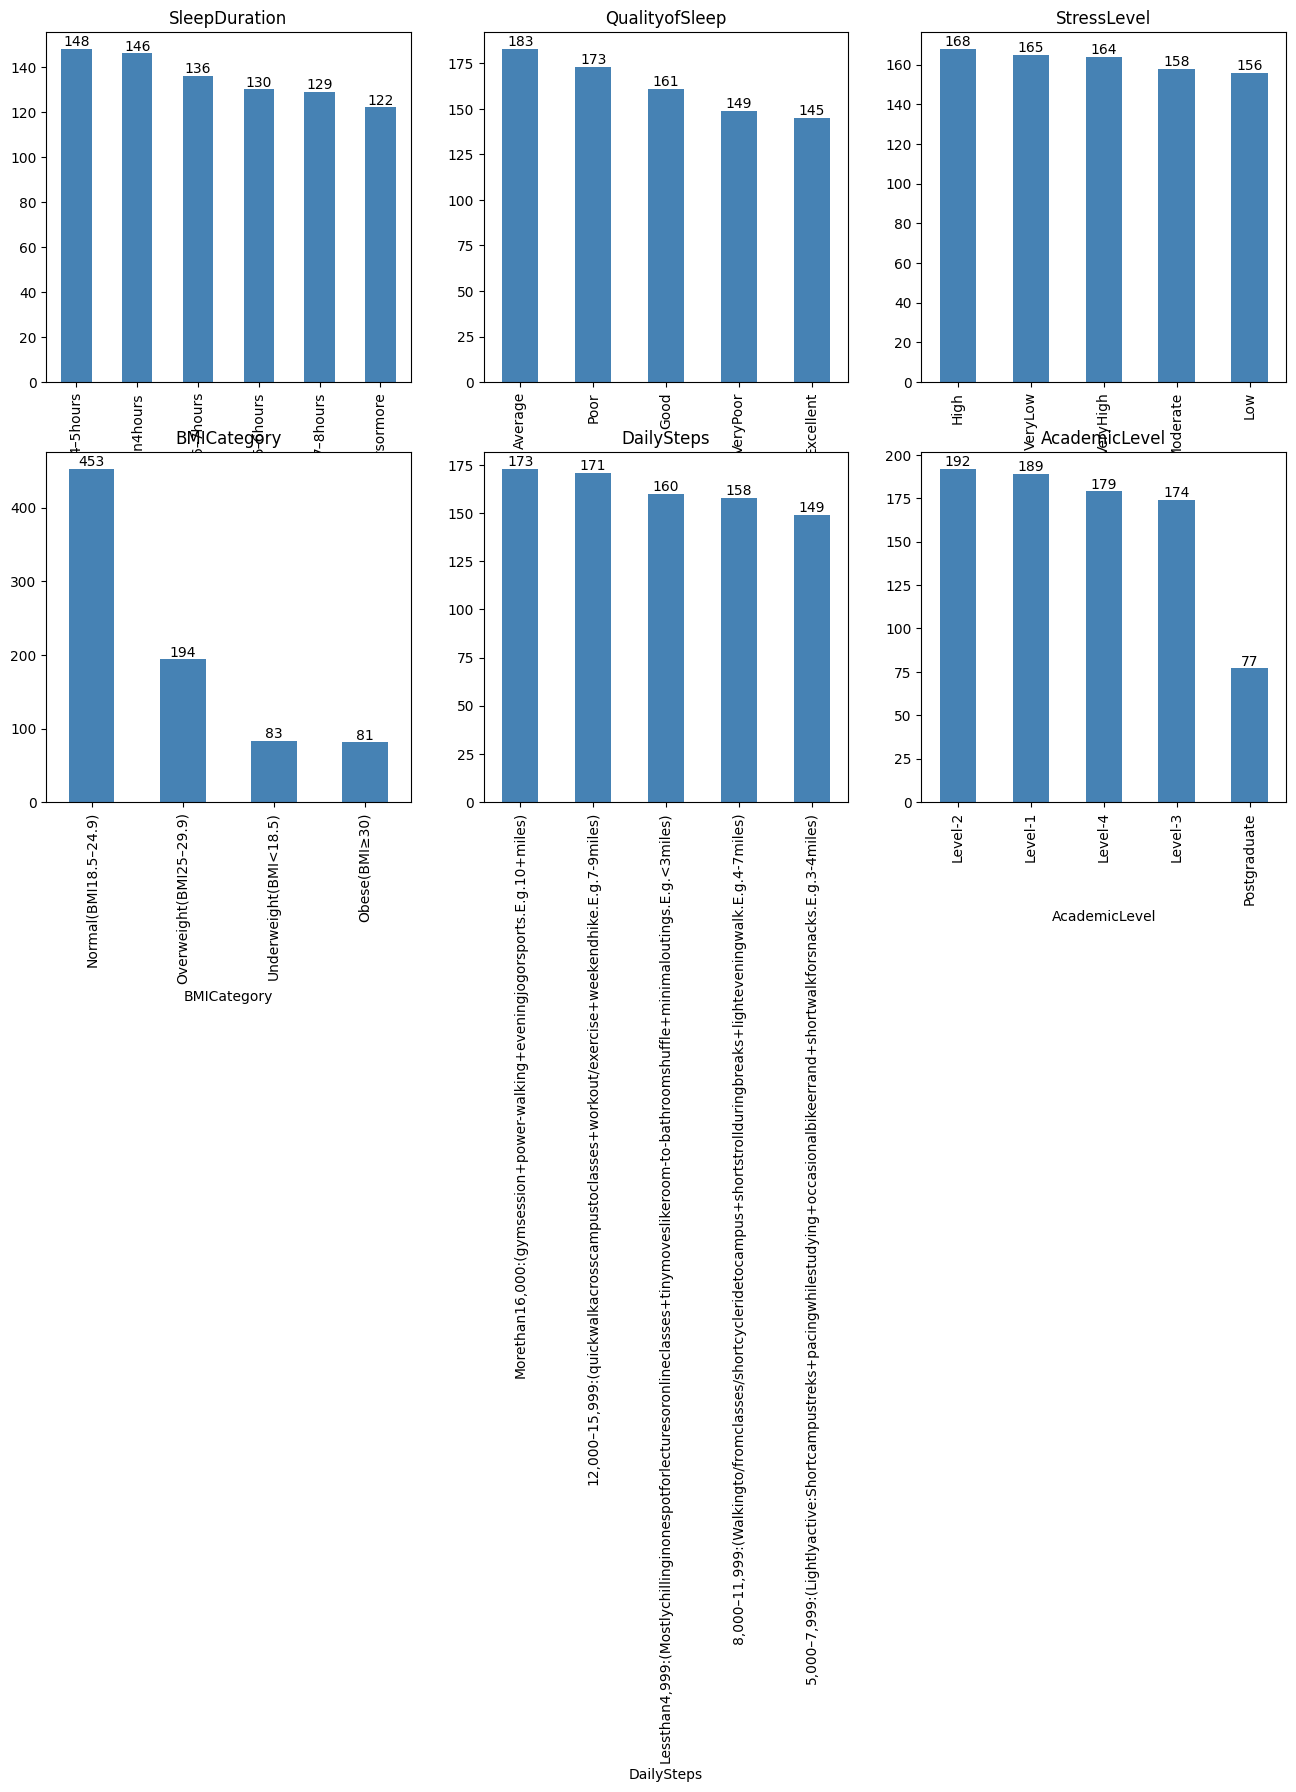

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flat, ['SleepDuration', 'QualityofSleep', 'StressLevel','BMICategory', 'DailySteps', 'AcademicLevel']):
    vc = df[col].value_counts()
    vc.plot(kind='bar', ax=ax, color='steelblue')
    ax.bar_label(ax.containers[0])
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

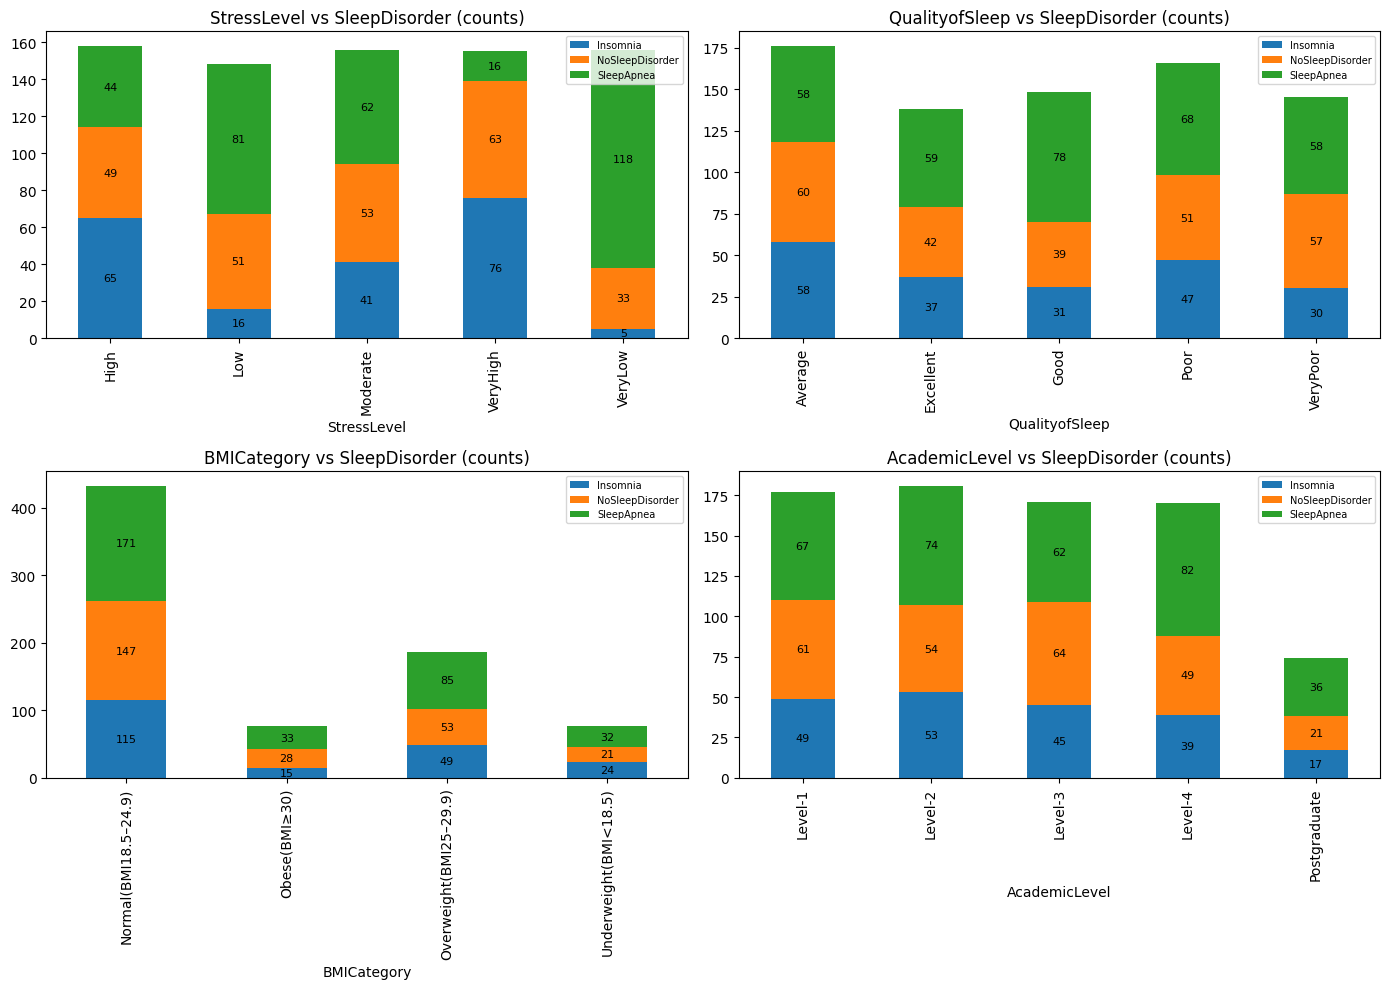

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, ['StressLevel', 'QualityofSleep', 'BMICategory', 'AcademicLevel']):
    ct = pd.crosstab(df[col], df['SleepDisorder'])
    ct.plot(kind='bar', stacked=True, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', label_type='center', fontsize=8)
    ax.set_title(f'{col} vs SleepDisorder (counts)')
    ax.tick_params(axis='x', rotation=90)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

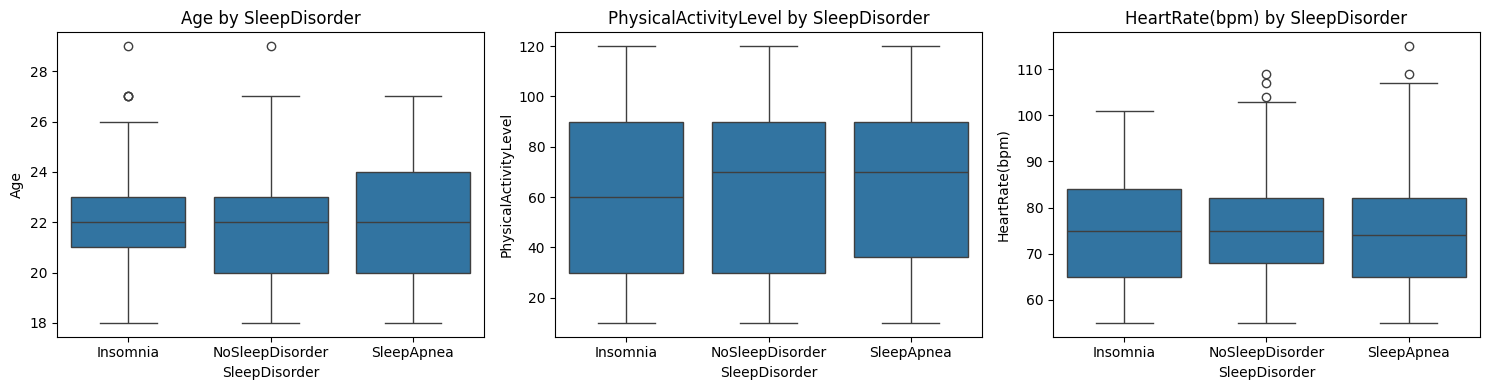

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Age', 'PhysicalActivityLevel', 'HeartRate(bpm)']):
    sns.boxplot(data=df, x='SleepDisorder', y=col, ax=ax)
    ax.set_title(f'{col} by SleepDisorder')
plt.tight_layout()
plt.show()

In [ ]:
print(df['Gender'].value_counts(dropna=False))

Gender
Male                 408
Female               376
Prefer not to say     27
Name: count, dtype: int64


In [ ]:
df

,Department,Gender,Age,SleepDuration,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,BloodPressure(systolic/diastolic),HeartRate(bpm),DailySteps,AcademicLevel,SleepDisorder
0,Economics,Female,24,Lessthan4hours,Poor,30,VeryLow,Obese(BMI≥30),118/80,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Postgraduate,Insomnia
1,EEE,Male,20,5–6hours,VeryPoor,100,Low,Overweight(BMI25–29.9),117/70,70.0,"Morethan16,000:(gymsession+power-walking+eveni...",Level-1,NoSleepDisorder
2,NE,Male,21,5–6hours,Good,110,Low,Normal(BMI18.5–24.9),124/74,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-2,SleepApnea
3,DVM,Male,22,7–8hours,VeryPoor,36,Low,Normal(BMI18.5–24.9),119/65,83.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-4,SleepApnea
4,CSE,Female,20,6–7hours,Average,100,Moderate,Overweight(BMI25–29.9),117/77,85.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-2,SleepApnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
806,ME,Female,24,5–6hours,Average,20,High,Normal(BMI18.5–24.9),114/74,62.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-3,Insomnia
807,DVM,Male,24,8hoursormore,Good,100,VeryHigh,Normal(BMI18.5–24.9),106/78,93.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-1,NoSleepDisorder
808,Economics,Male,23,4–5hours,VeryPoor,120,Low,Overweight(BMI25–29.9),124/88,81.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-1,NoSleepDisorder
809,CSE,Female,19,6–7hours,Poor,100,VeryHigh,Normal(BMI18.5–24.9),128/82,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-3,Insomnia


In [ ]:


df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1,"Prefer not to say":2})

In [ ]:
df.head()

,Department,Gender,Age,SleepDuration,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,BloodPressure(systolic/diastolic),HeartRate(bpm),DailySteps,AcademicLevel,SleepDisorder
0,Economics,1,24,Lessthan4hours,Poor,30,VeryLow,Obese(BMI≥30),118/80,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Postgraduate,Insomnia
1,EEE,0,20,5–6hours,VeryPoor,100,Low,Overweight(BMI25–29.9),117/70,70.0,"Morethan16,000:(gymsession+power-walking+eveni...",Level-1,NoSleepDisorder
2,NE,0,21,5–6hours,Good,110,Low,Normal(BMI18.5–24.9),124/74,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-2,SleepApnea
3,DVM,0,22,7–8hours,VeryPoor,36,Low,Normal(BMI18.5–24.9),119/65,83.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-4,SleepApnea
4,CSE,1,20,6–7hours,Average,100,Moderate,Overweight(BMI25–29.9),117/77,85.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-2,SleepApnea


In [ ]:
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - df.shape[0]} duplicate rows")
print("Rows with missing SleepDisorder (target):", df['SleepDisorder'].isnull().sum())
df = df.dropna(subset=['SleepDisorder']).reset_index(drop=True)
print("Shape after dropping unlabeled rows:", df.shape)

Dropped 0 duplicate rows
Rows with missing SleepDisorder (target): 38
Shape after dropping unlabeled rows: (773, 13)


In [ ]:
df

,Department,Gender,Age,SleepDuration,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,BloodPressure(systolic/diastolic),HeartRate(bpm),DailySteps,AcademicLevel,SleepDisorder
0,Economics,1,24,Lessthan4hours,Poor,30,VeryLow,Obese(BMI≥30),118/80,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Postgraduate,Insomnia
1,EEE,0,20,5–6hours,VeryPoor,100,Low,Overweight(BMI25–29.9),117/70,70.0,"Morethan16,000:(gymsession+power-walking+eveni...",Level-1,NoSleepDisorder
2,NE,0,21,5–6hours,Good,110,Low,Normal(BMI18.5–24.9),124/74,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-2,SleepApnea
3,DVM,0,22,7–8hours,VeryPoor,36,Low,Normal(BMI18.5–24.9),119/65,83.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-4,SleepApnea
4,CSE,1,20,6–7hours,Average,100,Moderate,Overweight(BMI25–29.9),117/77,85.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-2,SleepApnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...
768,ME,1,24,5–6hours,Average,20,High,Normal(BMI18.5–24.9),114/74,62.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-3,Insomnia
769,DVM,0,24,8hoursormore,Good,100,VeryHigh,Normal(BMI18.5–24.9),106/78,93.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-1,NoSleepDisorder
770,Economics,0,23,4–5hours,VeryPoor,120,Low,Overweight(BMI25–29.9),124/88,81.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-1,NoSleepDisorder
771,CSE,1,19,6–7hours,Poor,100,VeryHigh,Normal(BMI18.5–24.9),128/82,65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-3,Insomnia


In [ ]:
print("BloodPressure Missing:", df['BloodPressure(systolic/diastolic)'].isnull().sum())

BloodPressure Missing: 60


In [ ]:
df_encoded = df.copy()
df_encoded[["Systolic", "Diastolic"]] = df_encoded["BloodPressure(systolic/diastolic)"].str.split("/", expand=True)
df_encoded["Systolic"] = pd.to_numeric(df_encoded["Systolic"], errors='coerce')
df_encoded["Diastolic"] = pd.to_numeric(df_encoded["Diastolic"], errors='coerce')
df_encoded = df_encoded.drop(columns=["BloodPressure(systolic/diastolic)"])


In [ ]:
df_encoded

,Department,Gender,Age,SleepDuration,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,HeartRate(bpm),DailySteps,AcademicLevel,SleepDisorder,Systolic,Diastolic
0,Economics,1,24,Lessthan4hours,Poor,30,VeryLow,Obese(BMI≥30),65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Postgraduate,Insomnia,118.0,80.0
1,EEE,0,20,5–6hours,VeryPoor,100,Low,Overweight(BMI25–29.9),70.0,"Morethan16,000:(gymsession+power-walking+eveni...",Level-1,NoSleepDisorder,117.0,70.0
2,NE,0,21,5–6hours,Good,110,Low,Normal(BMI18.5–24.9),65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-2,SleepApnea,124.0,74.0
3,DVM,0,22,7–8hours,VeryPoor,36,Low,Normal(BMI18.5–24.9),83.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-4,SleepApnea,119.0,65.0
4,CSE,1,20,6–7hours,Average,100,Moderate,Overweight(BMI25–29.9),85.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-2,SleepApnea,117.0,77.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
768,ME,1,24,5–6hours,Average,20,High,Normal(BMI18.5–24.9),62.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-3,Insomnia,114.0,74.0
769,DVM,0,24,8hoursormore,Good,100,VeryHigh,Normal(BMI18.5–24.9),93.0,"12,000–15,999:(quickwalkacrosscampustoclasses+...",Level-1,NoSleepDisorder,106.0,78.0
770,Economics,0,23,4–5hours,VeryPoor,120,Low,Overweight(BMI25–29.9),81.0,"Lessthan4,999:(Mostlychillinginonespotforlectu...",Level-1,NoSleepDisorder,124.0,88.0
771,CSE,1,19,6–7hours,Poor,100,VeryHigh,Normal(BMI18.5–24.9),65.0,"8,000–11,999:(Walkingto/fromclasses/shortcycle...",Level-3,Insomnia,128.0,82.0


In [ ]:
sleep_map = {"VeryPoor": 0, "Poor": 1, "Average": 2, "Good": 3, "Excellent": 4}
stress_map = {"VeryLow": 0, "Low": 1, "Moderate": 2, "High": 3, "VeryHigh": 4}
academic_map = {"Level-1": 0, "Level-2": 1, "Level-3": 2, "Level-4": 3, "Postgraduate": 4}
bmi_map = {"Underweight(BMI<18.5)": 0, "Normal(BMI18.5–24.9)": 1,"Overweight(BMI25–29.9)": 2, "Obese(BMI≥30)": 3}

ordinal_maps = {"QualityofSleep": sleep_map, "StressLevel": stress_map,
                "AcademicLevel": academic_map, "BMICategory": bmi_map}

for col, mapping in ordinal_maps.items():
    actual = set(df_encoded[col].dropna().unique())
    expected = set(mapping.keys())
    unmatched = actual - expected
    if unmatched:
        print(f"WARNING: unmapped values in {col}: {unmatched}")
    else:
        print(f"{col}: all values match the mapping")
    df_encoded[col] = df_encoded[col].map(mapping)

QualityofSleep: all values match the mapping
StressLevel: all values match the mapping
AcademicLevel: all values match the mapping
BMICategory: all values match the mapping


In [ ]:
import re
def extract_numeric_midpoint(value, default=np.nan):
    if pd.isna(value):
        return default
    s = str(value).split('(')[0]
    nums = re.findall(r'\d+(?:,\d{3})*', s)
    nums = [float(n.replace(',', '')) for n in nums]
    if not nums:
        return default
    return sum(nums) / len(nums)

df_encoded['SleepDuration_hrs'] = df_encoded['SleepDuration'].apply(extract_numeric_midpoint)
df_encoded['DailySteps_num'] = df_encoded['DailySteps'].apply(extract_numeric_midpoint)
df_encoded = df_encoded.drop(columns=['SleepDuration', 'DailySteps'])

print(df_encoded[['SleepDuration_hrs', 'DailySteps_num']].isnull().sum())
df_encoded[['SleepDuration_hrs', 'DailySteps_num']].describe()

SleepDuration_hrs    0
DailySteps_num       0
dtype: int64


,SleepDuration_hrs,DailySteps_num
count,773.000000,773.000000
mean,5.913972,10432.879043
std,1.458639,4238.450970
min,4.000000,4999.000000
25%,4.500000,6499.500000
50%,5.500000,9999.500000
75%,7.500000,13999.500000
max,8.000000,16000.000000


In [ ]:
dept_counts = df_encoded['Department'].value_counts()
print(dept_counts)

MIN_DEPT_COUNT = 4
rare_depts = dept_counts[dept_counts < MIN_DEPT_COUNT].index
df_encoded['Department'] = df_encoded['Department'].replace(rare_depts, 'Other')
print("\nAfter grouping rare departments:")
print(df_encoded['Department'].value_counts())

df_encoded = pd.get_dummies(df_encoded, columns=['Department'], drop_first=True, dtype=int)
df_encoded.info()

Department
CSE                 149
EEE                  81
CivilEngineering     60
ECE                  52
ME                   51
Economics            50
AIE                  47
Statistics           42
Mathematics          42
Agriculture          40
Socialwork           34
FPE                  33
NE                   33
DVM                  32
GDS                  27
Name: count, dtype: int64

After grouping rare departments:
Department
CSE                 149
EEE                  81
CivilEngineering     60
ECE                  52
ME                   51
Economics            50
AIE                  47
Statistics           42
Mathematics          42
Agriculture          40
Socialwork           34
FPE                  33
NE                   33
DVM                  32
GDS                  27
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 773 entries, 0 to 772
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ----

In [ ]:
from sklearn.preprocessing import LabelEncoder

print(df_encoded["SleepDisorder"].value_counts(dropna=False))
le = LabelEncoder()
df_encoded["SleepDisorder"] = le.fit_transform(df_encoded["SleepDisorder"])
df_encoded["SleepDisorder"] = df_encoded.pop("SleepDisorder")
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Final encoded shape:", df_encoded.shape)
print("\nColumns still containing missing values (to be filled AFTER the split):")
print(df_encoded.isnull().sum()[df_encoded.isnull().sum() > 0])

SleepDisorder
SleepApnea         321
NoSleepDisorder    249
Insomnia           203
Name: count, dtype: int64
Label mapping: {'Insomnia': np.int64(0), 'NoSleepDisorder': np.int64(1), 'SleepApnea': np.int64(2)}
Final encoded shape: (773, 27)

Columns still containing missing values (to be filled AFTER the split):
HeartRate(bpm)    70
Systolic          60
Diastolic         60
dtype: int64


In [ ]:
df_encoded

,Gender,Age,QualityofSleep,PhysicalActivityLevel,StressLevel,BMICategory,HeartRate(bpm),AcademicLevel,Systolic,Diastolic,SleepDuration_hrs,DailySteps_num,Department_Agriculture,Department_CSE,Department_CivilEngineering,Department_DVM,Department_ECE,Department_EEE,Department_Economics,Department_FPE,Department_GDS,Department_ME,Department_Mathematics,Department_NE,Department_Socialwork,Department_Statistics,SleepDisorder
0,1,24,1,30,0,3,65.0,4,118.0,80.0,4.0,9999.5,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,0,20,0,100,1,2,70.0,0,117.0,70.0,5.5,16000.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
2,0,21,3,110,1,1,65.0,1,124.0,74.0,5.5,9999.5,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2
3,0,22,0,36,1,1,83.0,3,119.0,65.0,7.5,4999.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,1,20,2,100,2,2,85.0,1,117.0,77.0,6.5,13999.5,0,1,0,0,0,0,0,0,0,0,0,0,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
768,1,24,2,20,3,1,62.0,2,114.0,74.0,5.5,4999.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
769,0,24,3,100,4,1,93.0,0,106.0,78.0,8.0,13999.5,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1
770,0,23,0,120,1,2,81.0,0,124.0,88.0,4.5,4999.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
771,1,19,1,100,4,1,65.0,2,128.0,82.0,6.5,9999.5,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


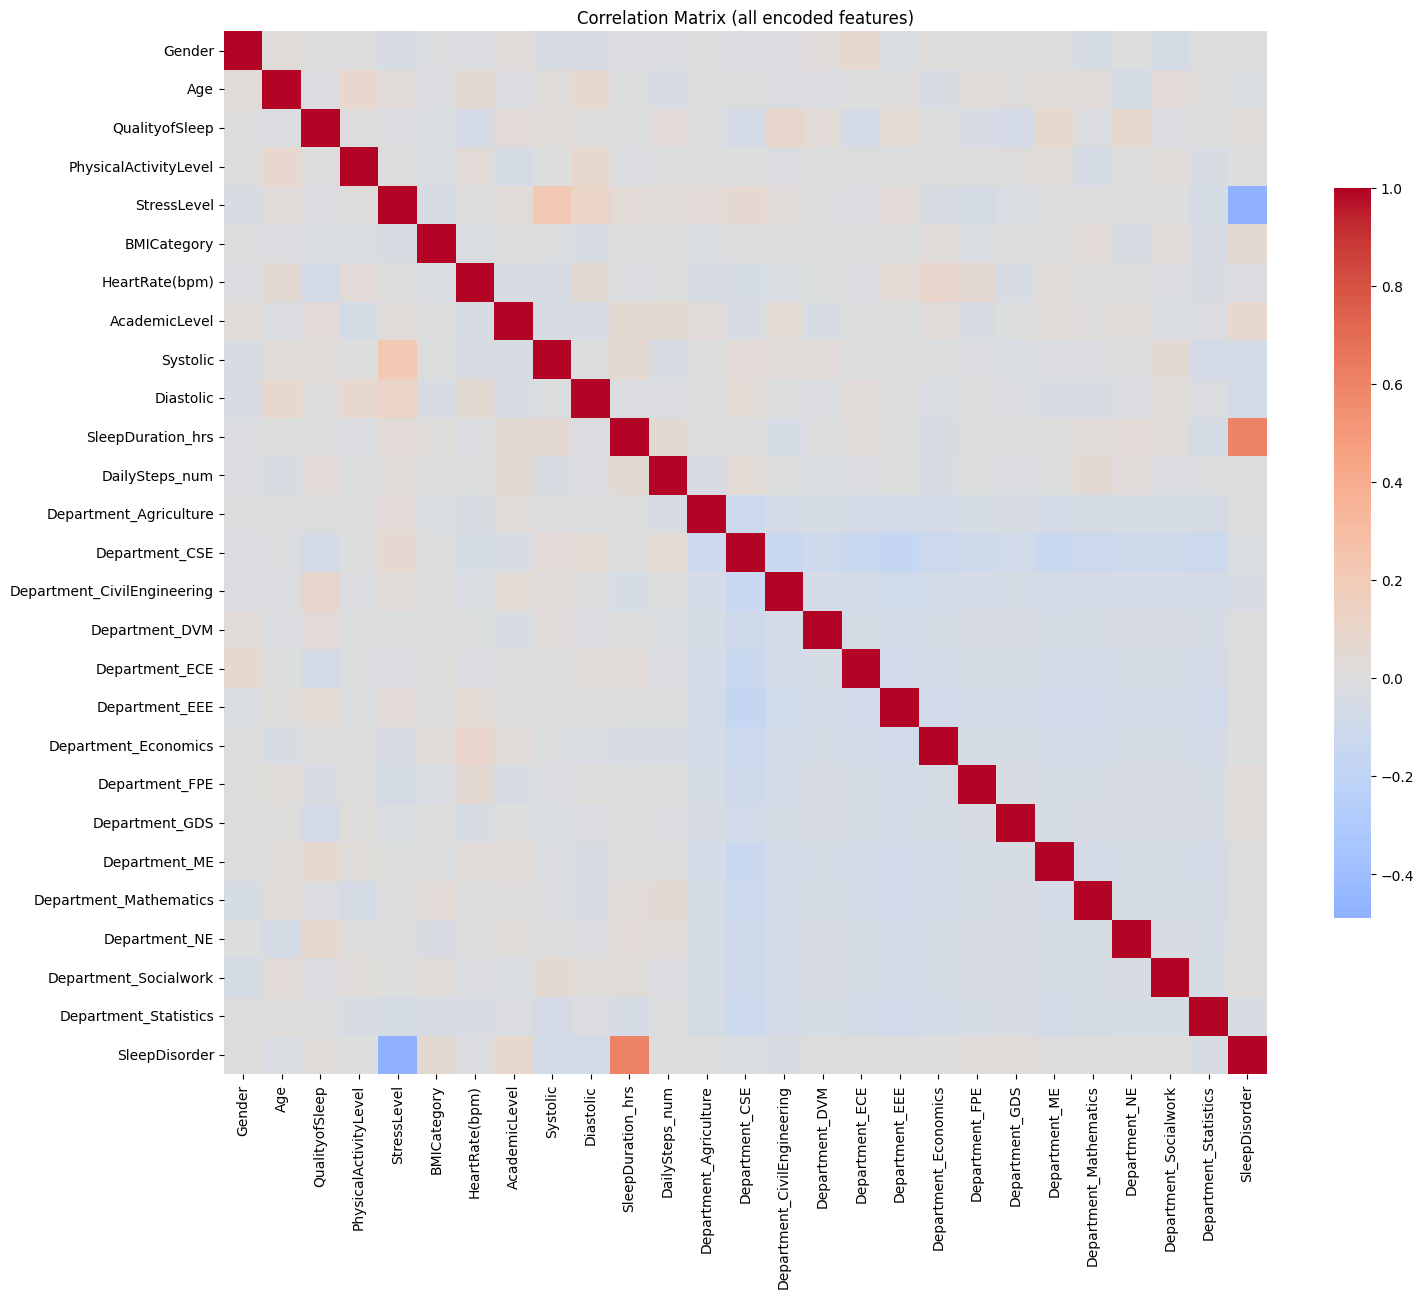

Top 15 features by |correlation| with SleepDisorder:
SleepDuration_hrs              0.602373
StressLevel                    0.489199
Systolic                       0.072892
Diastolic                      0.071549
AcademicLevel                  0.070596
BMICategory                    0.048750
Department_Statistics          0.045226
Department_CivilEngineering    0.036806
Department_FPE                 0.031341
Department_CSE                 0.027342
Age                            0.025371
Department_GDS                 0.025068
QualityofSleep                 0.022088
Gender                         0.016752
Department_Socialwork          0.014112
Name: SleepDisorder, dtype: float64


In [ ]:
corr_matrix = df_encoded.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
plt.title("Correlation Matrix (all encoded features)")
plt.tight_layout()
plt.show()

target_corr = corr_matrix['SleepDisorder'].drop('SleepDisorder').abs().sort_values(ascending=False)
print("Top 15 features by |correlation| with SleepDisorder:")
print(target_corr.head(15))

## Train/Test Split , Imputation , SMOTE , Scaling
Everything from here on is fit **only on the training set**

In [ ]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(['SleepDisorder'], axis=1)
y = df_encoded['SleepDisorder']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("X_train:", X_train.shape, "\nX_test:", X_test.shape)

print("\nTrain class balance:\n", y_train.value_counts(normalize=True))
print("\nTest class balance:\n", y_test.value_counts(normalize=True))

X_train: (618, 26) 
X_test: (155, 26)

Train class balance:
 SleepDisorder
2    0.415858
1    0.322006
0    0.262136
Name: proportion, dtype: float64

Test class balance:
 SleepDisorder
2    0.412903
1    0.322581
0    0.264516
Name: proportion, dtype: float64


### Filling missing values


In [ ]:
impute_cols = ['HeartRate(bpm)', 'Systolic', 'Diastolic']

X_train = X_train.copy()
X_test = X_test.copy()

train_medians = X_train[impute_cols].median()
print("Medians computed from the TRAINING set only:\n", train_medians)

X_train[impute_cols] = X_train[impute_cols].fillna(train_medians)
X_test[impute_cols] = X_test[impute_cols].fillna(train_medians)

print("\nRemaining missing values to train:", X_train.isnull().sum().sum(),
      " test:", X_test.isnull().sum().sum())

Medians computed from the TRAINING set only:
 HeartRate(bpm)     74.0
Systolic          114.0
Diastolic          75.0
dtype: float64

Remaining missing values to train: 0  test: 0


### SMOTE for balancing the training set


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", X_train.shape, dict(y_train.value_counts()))
print("After SMOTE: ", X_train_res.shape, dict(y_train_res.value_counts()))

Before SMOTE: (618, 26) {2: np.int64(257), 1: np.int64(199), 0: np.int64(162)}
After SMOTE:  (771, 26) {0: np.int64(257), 1: np.int64(257), 2: np.int64(257)}


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_res_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

## Modeling

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, model, X_te, y_te):
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    print(f" {name} ")
    print("Test Accuracy:", round(acc, 4))
    print(classification_report(y_te, y_pred, target_names=le.classes_))
    cm = confusion_matrix(y_te, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues')
    plt.title(f'{name} — Confusion Matrix')
    plt.show()
    return acc

In [ ]:
!pip install catboost
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.8 MB/s eta 0:00:00


Best DT params: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20}
Best CV accuracy: 0.7043
 Decision Tree (tuned) 
Test Accuracy: 0.6581
                 precision    recall  f1-score   support

       Insomnia       0.68      0.78      0.73        41
NoSleepDisorder       0.52      0.48      0.50        50
     SleepApnea       0.74      0.72      0.73        64

       accuracy                           0.66       155
      macro avg       0.65      0.66      0.65       155
   weighted avg       0.65      0.66      0.66       155



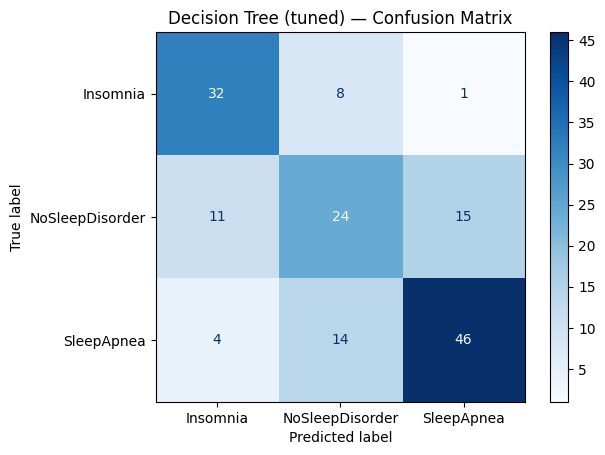

In [ ]:
dt_params = {'max_depth': [3, 5, 7, 10, None], 'min_samples_leaf': [1, 5, 10, 20], 'criterion': ['gini', 'entropy']}

dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_params, cv=cv, scoring='accuracy', n_jobs=-1)
dt_grid.fit(X_train_res, y_train_res)

print("Best DT params:", dt_grid.best_params_)
print("Best CV accuracy:", round(dt_grid.best_score_, 4))
best_dt = dt_grid.best_estimator_
acc_dt = evaluate("Decision Tree (tuned)", best_dt, X_test, y_test)

Best RF params: {'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV accuracy: 0.7497
 Random Forest (tuned) 
Test Accuracy: 0.6645
                 precision    recall  f1-score   support

       Insomnia       0.74      0.78      0.76        41
NoSleepDisorder       0.51      0.52      0.51        50
     SleepApnea       0.74      0.70      0.72        64

       accuracy                           0.66       155
      macro avg       0.66      0.67      0.67       155
   weighted avg       0.67      0.66      0.66       155



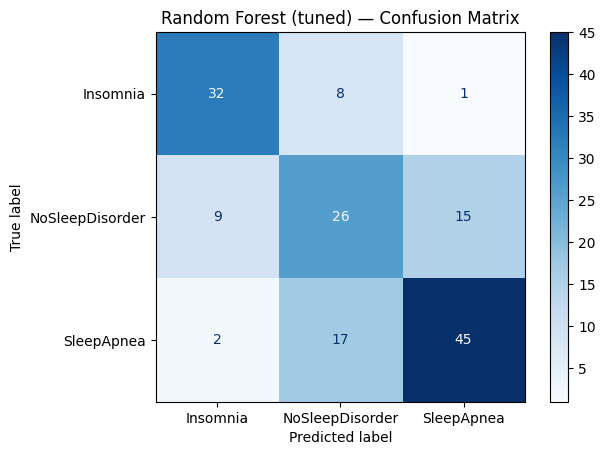

In [ ]:
rf_params = {'n_estimators': [100, 200, 300], 'max_depth': [5, 10, 15, None], 'min_samples_leaf': [1, 5, 10]}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), rf_params, cv=cv, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_res, y_train_res)

print("Best RF params:", rf_grid.best_params_)
print("Best CV accuracy:", round(rf_grid.best_score_, 4))
best_rf = rf_grid.best_estimator_
acc_rf = evaluate("Random Forest (tuned)", best_rf, X_test, y_test)

 AdaBoost 
Test Accuracy: 0.671
                 precision    recall  f1-score   support

       Insomnia       0.86      0.61      0.71        41
NoSleepDisorder       0.50      0.76      0.60        50
     SleepApnea       0.82      0.64      0.72        64

       accuracy                           0.67       155
      macro avg       0.73      0.67      0.68       155
   weighted avg       0.73      0.67      0.68       155



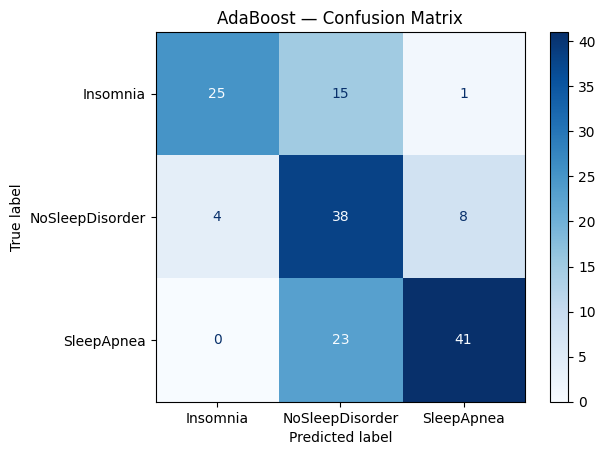

In [ ]:
abc = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)
abc.fit(X_train_res, y_train_res)
acc_abc = evaluate("AdaBoost", abc, X_test, y_test)

 Gradient Boosting 
Test Accuracy: 0.6968
                 precision    recall  f1-score   support

       Insomnia       0.78      0.78      0.78        41
NoSleepDisorder       0.56      0.58      0.57        50
     SleepApnea       0.76      0.73      0.75        64

       accuracy                           0.70       155
      macro avg       0.70      0.70      0.70       155
   weighted avg       0.70      0.70      0.70       155



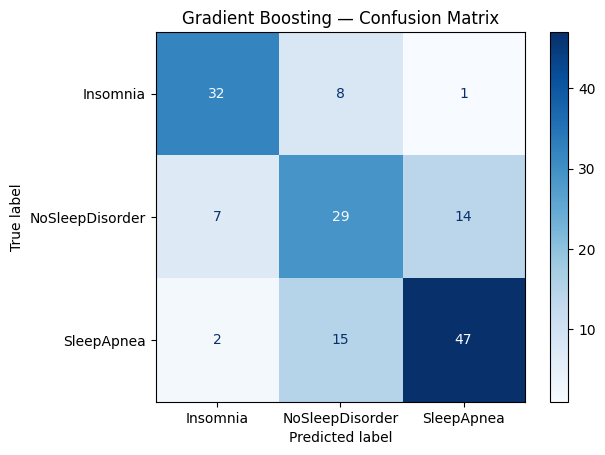

In [ ]:
gbc = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)
gbc.fit(X_train_res, y_train_res)
acc_gbc = evaluate("Gradient Boosting", gbc, X_test, y_test)

 Logistic Regression (scaled) 
Test Accuracy: 0.6903
                 precision    recall  f1-score   support

       Insomnia       0.74      0.78      0.76        41
NoSleepDisorder       0.55      0.58      0.56        50
     SleepApnea       0.78      0.72      0.75        64

       accuracy                           0.69       155
      macro avg       0.69      0.69      0.69       155
   weighted avg       0.70      0.69      0.69       155



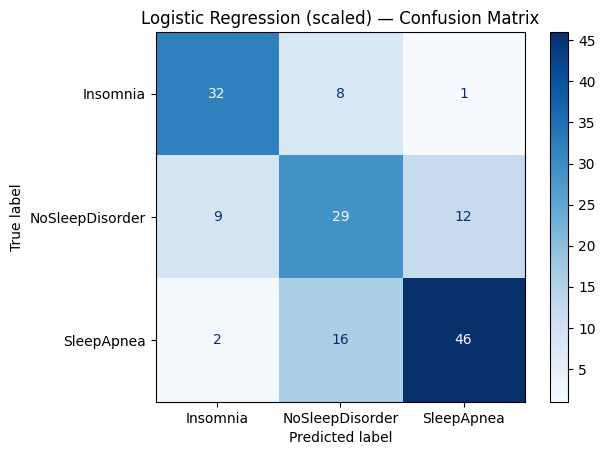

In [ ]:
lr = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
lr.fit(X_train_res_scaled, y_train_res)
acc_lr = evaluate("Logistic Regression (scaled)", lr, X_test_scaled, y_test)

 XGBoost 
Test Accuracy: 0.6387
                 precision    recall  f1-score   support

       Insomnia       0.72      0.68      0.70        41
NoSleepDisorder       0.47      0.50      0.49        50
     SleepApnea       0.73      0.72      0.72        64

       accuracy                           0.64       155
      macro avg       0.64      0.63      0.64       155
   weighted avg       0.64      0.64      0.64       155



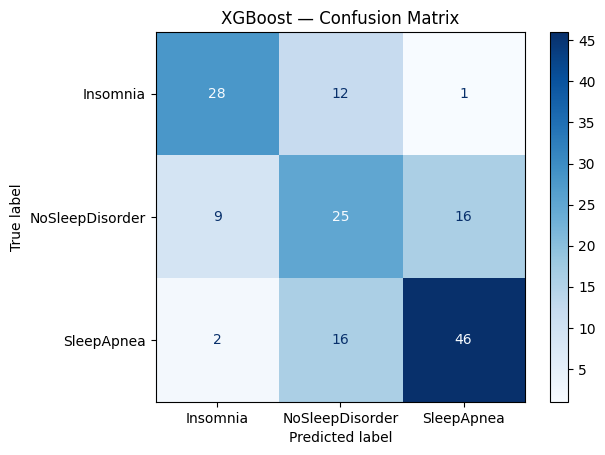

In [ ]:
xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=RANDOM_STATE, eval_metric='mlogloss')
xgb.fit(X_train_res, y_train_res)
acc_xgb = evaluate("XGBoost", xgb, X_test, y_test)

 CatBoost 
Test Accuracy: 0.7161
                 precision    recall  f1-score   support

       Insomnia       0.78      0.78      0.78        41
NoSleepDisorder       0.58      0.64      0.61        50
     SleepApnea       0.80      0.73      0.76        64

       accuracy                           0.72       155
      macro avg       0.72      0.72      0.72       155
   weighted avg       0.72      0.72      0.72       155



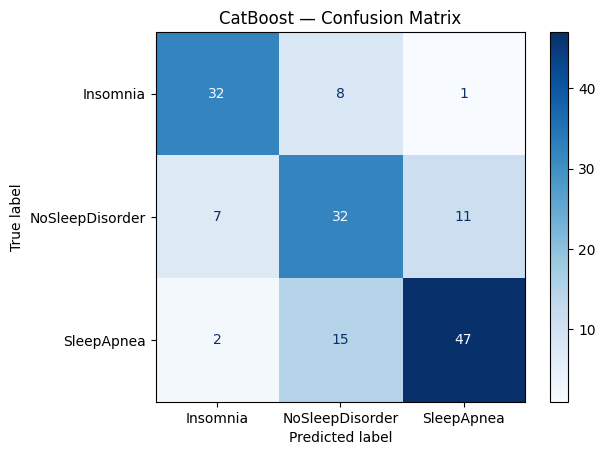

In [ ]:
cbc = CatBoostClassifier(iterations=200, learning_rate=0.05, depth=5, random_state=RANDOM_STATE, verbose=0)
cbc.fit(X_train_res, y_train_res)
acc_cbc = evaluate("CatBoost", cbc, X_test, y_test)

In [ ]:
results = {"Decision Tree (tuned)": acc_dt, "Random Forest (tuned)": acc_rf, "AdaBoost": acc_abc, "Gradient Boosting": acc_gbc,"Logistic Regression (scaled)": acc_lr, "XGBoost": acc_xgb, "CatBoost": acc_cbc}

results_df = pd.Series(results).sort_values(ascending=False).rename("Test Accuracy")
print(results_df)

CatBoost                        0.716129
Gradient Boosting               0.696774
Logistic Regression (scaled)    0.690323
AdaBoost                        0.670968
Random Forest (tuned)           0.664516
Decision Tree (tuned)           0.658065
XGBoost                         0.638710
Name: Test Accuracy, dtype: float64


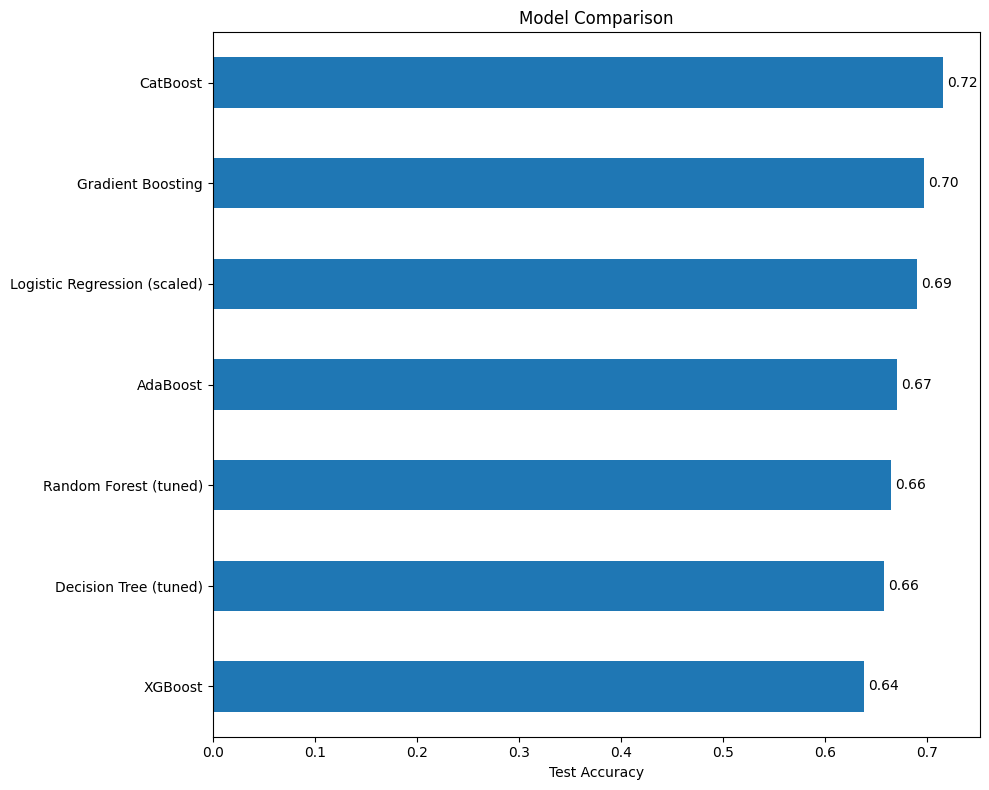

In [ ]:
plt.figure(figsize=(10,8))
ax = results_df.plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Test Accuracy')
plt.title('Model Comparison')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f',  label_type='edge', padding=3)
plt.tight_layout()
plt.show()